# ESC contrast budget as a render tree

Renders the **ESC red-arm contrast budget** (`budgets_esc`, PR #3 `kvangorkom/refactor`)
as a budgie tree, in the vertical packed-outline format used by the
`schmidt_ESP_template` exposure-time budget. All 17 terms, one page.

## Which values these are

The refactor's budget is built in three stages (`docs/contrast_red.ipynb`):

```python
budget_template = ContrastBudget('esc_red_input.yaml')   # notional placeholder values
budget_update   = Budget('esc_red_input_dev.yaml')       # partial budget, real values
budget_template.update_from_budget(budget_update)        # overlay
budget_template.export_to_yaml('esc_red_output.yaml')    # final
```

**The terms below are the final, post-overlay values**, verified equal term-by-term
to the committed `esc_red_output.yaml` (total **7.4243e-09**). Reading only
`esc_red_input.yaml` gives the *notional* budget: 7 of the 17 leaves differ and the
total comes out **1.0582e-08**, 43% high. Worth knowing, because `ContrastBudget`
loads the notional file happily and nothing signals that the overlay is missing.

The table is embedded so this notebook runs with only `budgie` installed.


## The 17 leaf terms (final values)

`Type` collapses the budget's two grouping levels (`system` / `type`) into the single `Type` column `build_tree` supports.


In [1]:
ROWS = [
    {
        "Name": "efc_chromatic_residuals",
        "CBE": 3.063893160579345e-11,
        "Allocation": 3e-09,
        "Type": "telescope / static"
    },
    {
        "Name": "polarization_aberrations",
        "CBE": 1e-10,
        "Allocation": 5e-10,
        "Type": "telescope / static"
    },
    {
        "Name": "scattering",
        "CBE": 1e-11,
        "Allocation": 5e-11,
        "Type": "telescope / static"
    },
    {
        "Name": "stray_light",
        "CBE": 1e-11,
        "Allocation": 1e-11,
        "Type": "telescope / static"
    },
    {
        "Name": "howfsc_residuals",
        "CBE": 1e-09,
        "Allocation": 1e-09,
        "Type": "telescope / dynamic"
    },
    {
        "Name": "llowfsc_residuals",
        "CBE": 1e-09,
        "Allocation": 3e-09,
        "Type": "telescope / dynamic"
    },
    {
        "Name": "efc_chromatic_residuals",
        "CBE": 6.252169667705855e-10,
        "Allocation": 3e-09,
        "Type": "esc / static"
    },
    {
        "Name": "polarization_aberrations",
        "CBE": 1e-10,
        "Allocation": 5e-10,
        "Type": "esc / static"
    },
    {
        "Name": "scattering",
        "CBE": 1e-11,
        "Allocation": 5e-11,
        "Type": "esc / static"
    },
    {
        "Name": "vvc_filtering_leakage",
        "CBE": 1.5073994353414168e-10,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "pixel_crosstalk",
        "CBE": 1e-11,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "dm_quantization",
        "CBE": 3.1913156064733044e-11,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "dm_voltage_noise",
        "CBE": 2.357746622286359e-10,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "ghosts",
        "CBE": 1e-11,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "resolved_source_leakage",
        "CBE": 1e-10,
        "Allocation": 1e-10,
        "Type": "esc / static"
    },
    {
        "Name": "howfsc_residuals",
        "CBE": 1e-09,
        "Allocation": 1e-09,
        "Type": "esc / dynamic"
    },
    {
        "Name": "llowfs_residuals",
        "CBE": 3e-09,
        "Allocation": 3e-09,
        "Type": "esc / dynamic"
    }
]

print(len(ROWS), 'leaf terms')


17 leaf terms


## Adapting the ESC budget

Two further things must be right, and both fail silently rather than erroring:

**1. Leaves only.** `ContrastBudget.load_tree_df()` flattens the *whole* tree -- 24 rows
for this budget: 17 leaves **plus 7 roll-up nodes** (`Total`, `telescope`, `static`, ...).
`build_tree` treats every row as a leaf and builds its own roll-ups, so feeding it the
full frame double-counts, roughly doubling the total and listing `static`/`dynamic`
twice. Pass only the leaves.

**2. Sum, not RSS.** The ESC budget's `roll_up_terms()` combines children with a plain
cumulative **sum**. budgie's default category op is `rss`, which on this budget gives
**3.52e-09** instead of **7.42e-09**. Hence `default_category_combine_op="sum"`.


In [2]:
from budgie.tree import build_tree, render_ascii, render_tikz

TYPES = sorted({r["Type"] for r in ROWS})
CONFIG = {
    # ESC rolls up by plain sum at every level (contrast_budget.roll_up_terms)
    "category_combine_ops": {t: "sum" for t in TYPES},
    "post_processing_chain": [
        {"op": "sum", "label": "Total system contrast", "op_label": r"$\Sigma$"},
    ],
}
node = build_tree(ROWS, config=CONFIG, default_category_combine_op="sum")

print("root CBE      =", f"{node.value:.4e}")
print("esc_red_output =  7.4243e-09")
print("closure check =", abs(node.value - 7.4243e-09) < 1e-12)
print("root alloc    =", f"{node.allocation:.4e}", "(sum of leaf allocations)")

over = [r for r in ROWS if r["CBE"] > r["Allocation"]]
print("\nover-allocated leaves:", len(over))
for r in over:
    print(f'   {r["Name"]:28s} {r["CBE"]:.2e} > {r["Allocation"]:.2e}   ({r["Type"]})')


root CBE      = 7.4243e-09
esc_red_output =  7.4243e-09
closure check = True
root alloc    = 1.5710e-08 (sum of leaf allocations)

over-allocated leaves: 2
   vvc_filtering_leakage        1.51e-10 > 1.00e-10   (esc / static)
   dm_voltage_noise             2.36e-10 > 1.00e-10   (esc / static)


## ASCII view


In [3]:
print(render_ascii(node, show="both"))


Total system contrast ... 7.4e-09 (1.6e-08 alloc)
├── $\Sigma$ telescope / static (subtotal) ... 1.5e-10 (3.6e-09 alloc)
│   ├── $\sum$ efc_chromatic_residuals ... 3.1e-11 (3.0e-09 alloc)
│   ├── $\sum$ polarization_aberrations ... 1.0e-10 (5.0e-10 alloc)
│   ├── $\sum$ scattering ... 1.0e-11 (5.0e-11 alloc)
│   └── $\sum$ stray_light ... 1.0e-11 (1.0e-11 alloc)
├── $\Sigma$ telescope / dynamic (subtotal) ... 2.0e-09 (4.0e-09 alloc)
│   ├── $\sum$ howfsc_residuals ... 1.0e-09 (1.0e-09 alloc)
│   └── $\sum$ llowfsc_residuals ... 1.0e-09 (3.0e-09 alloc)
├── $\Sigma$ esc / static (subtotal) ... 1.3e-09 (4.1e-09 alloc)
│   ├── $\sum$ efc_chromatic_residuals ... 6.3e-10 (3.0e-09 alloc)
│   ├── $\sum$ polarization_aberrations ... 1.0e-10 (5.0e-10 alloc)
│   ├── $\sum$ scattering ... 1.0e-11 (5.0e-11 alloc)
│   ├── $\sum$ vvc_filtering_leakage ... 1.5e-10 (1.0e-10 alloc)
│   ├── $\sum$ pixel_crosstalk ... 1.0e-11 (1.0e-10 alloc)
│   ├── $\sum$ dm_quantization ... 3.2e-11 (1.0e-10 alloc)
│   ├

## Vertical packed-outline render

budgie's own `layout="outline"` positions children with tikz `grow via three points`,
which places them at fixed offsets and cannot account for subtree heights -- nested
subtrees overlap. `schmidt_ESP_template` works around this by computing absolute
coordinates itself.

The renderer below is a compact version of that approach, adapted from
`budgets/exposure_time/render_tree.py`. It reuses budgie's colour styling
(`_tikz_style_block`, `_style_name`) so the per-`Type` fills match, and lays the
tree out vertically so every term fits on one page.


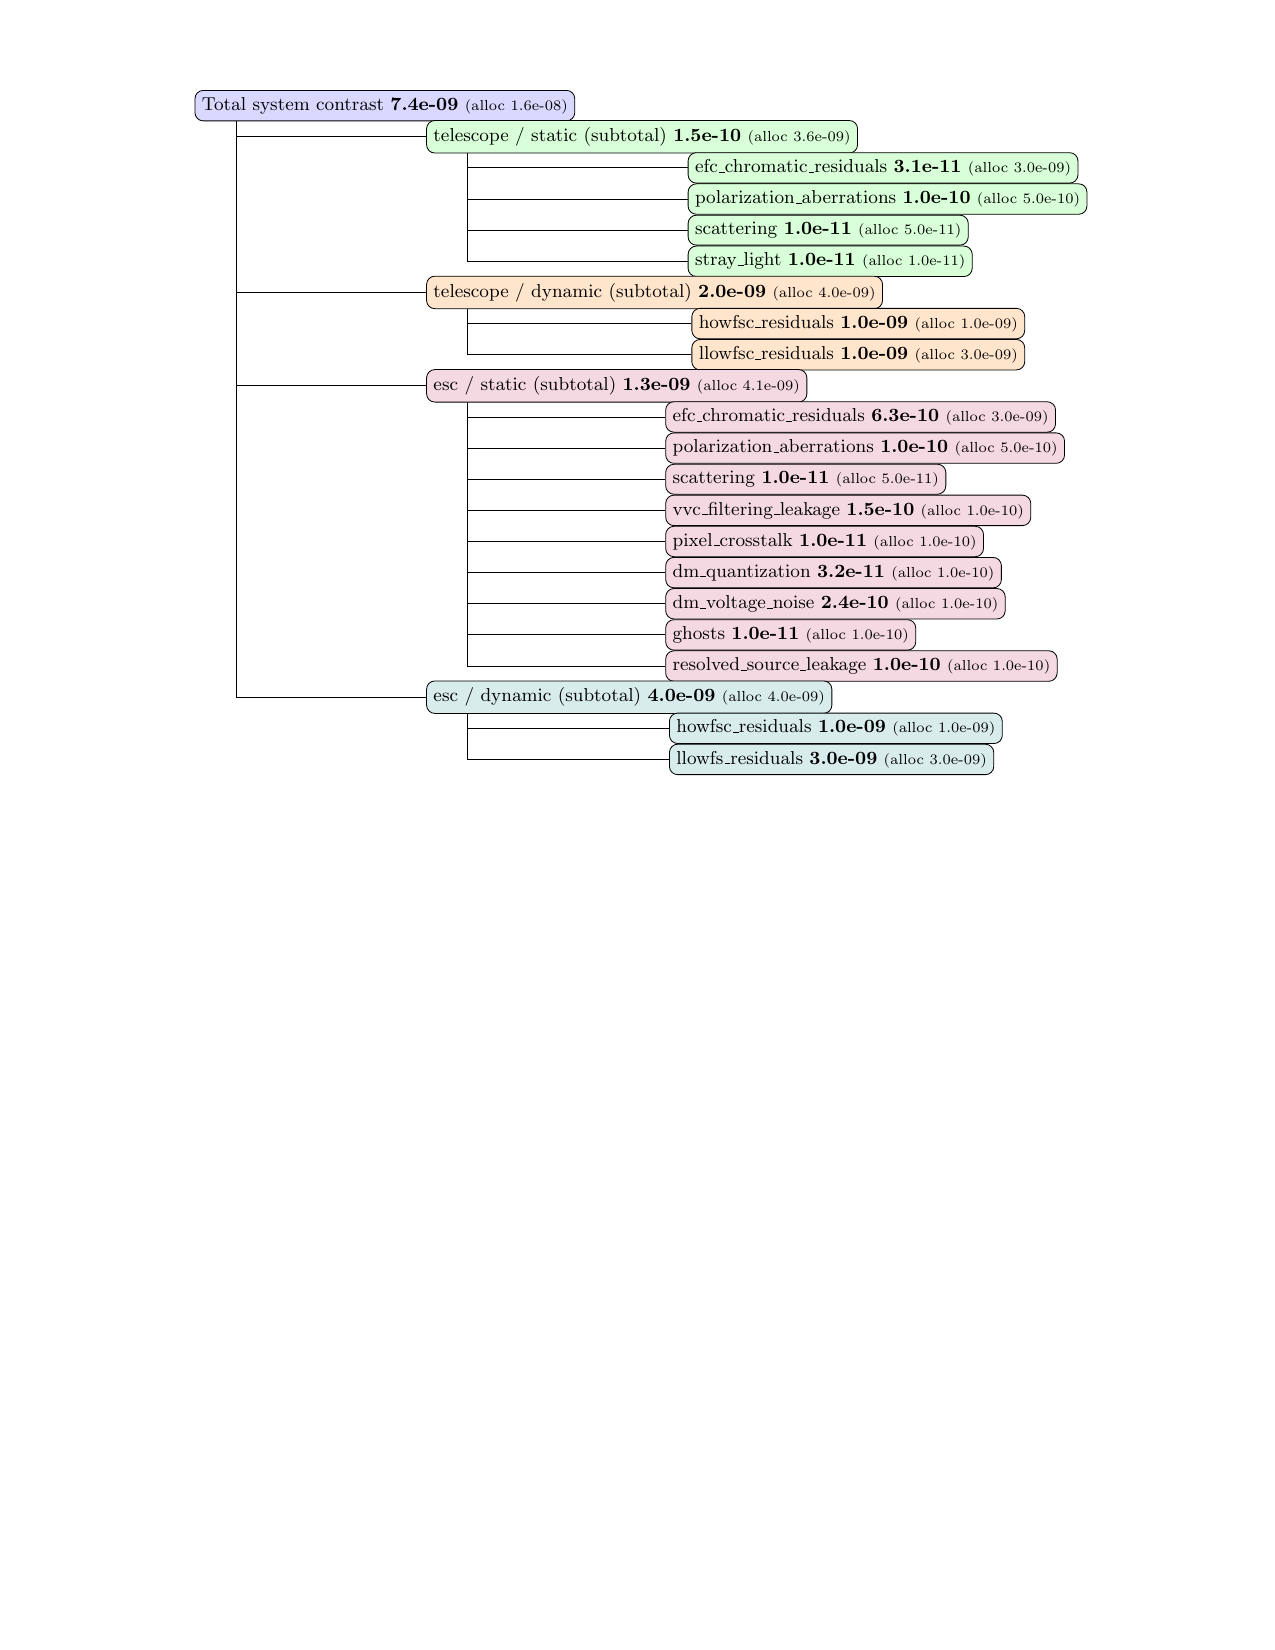

In [4]:
import subprocess, tempfile, shutil
from pathlib import Path
from IPython.display import Image
from budgie.tree import _style_name, _tikz_style_block

INDENT_EM, LINE_EM, EM_PER_CHAR, OVERLAP, EDGE_DROP = 1.5, 1.5, 0.45, 0.4, 2.0

def _plain(t):
    for tok in ("\\dotfill", "\\times", "\\sum", "\\,"):
        t = t.replace(tok, "")
    for ch in ("$", "\\", "{", "}"):
        t = t.replace(ch, "")
    return t

def _label(n):
    """Name + CBE, with the allocation in parentheses so margin is visible."""
    name = str(n.name).replace("_", r"\_")
    val = "N/A" if n.value is None else f"{n.value:.1e}"
    out = f"{name} \\textbf{{{val}}}"
    if n.allocation is not None:
        out += f" {{\\scriptsize (alloc {n.allocation:.1e})}}"
    return out

def _layout(n, x=0.0, y=0.0):
    """Place each child under its parent, indented; return positions + height."""
    pos = {id(n): (x, y)}
    if not n.children:
        return pos, LINE_EM
    cx = x + max(INDENT_EM, OVERLAP * len(_plain(_label(n))) * EM_PER_CHAR)
    cur, total = y - LINE_EM, LINE_EM
    for c in n.children:
        sub, h = _layout(c, cx, cur)
        pos.update(sub); cur -= h; total += h
    return pos, total

def render_vertical(root):
    pos, _ = _layout(root)
    nodes, edges = [], []
    def walk(n):
        nid = f"n{id(n)}"
        x, y = pos[id(n)]
        style = _style_name(str(n.metadata.get("Type", n.kind)))
        opts = f"draw, rounded corners, align=left, anchor=west, {style}"
        nodes.append(f"\\node[{opts}] ({nid}) at ({x:g}em,{y:g}em) {{{_label(n)}}};")
        for c in n.children:
            edges.append(f"\\draw ([xshift={EDGE_DROP:g}em]{nid}.south west) |- (n{id(c)}.west);")
        for c in n.children:
            walk(c)
    walk(root)
    return (_tikz_style_block(root, False)
            + "\\begin{tikzpicture}[every node/.style={font=\\small}]\n"
            + "\n".join(nodes + edges) + "\n\\end{tikzpicture}\n")

def one_page_png(body, dpi=150, out=None):
    """Scale the picture to fit a single letter page, rasterise for display."""
    doc = (r"\documentclass[letterpaper]{article}"
           r"\usepackage[margin=0.6in]{geometry}\usepackage{forest}\usepackage{xcolor}"
           r"\usepackage{adjustbox}\usetikzlibrary{trees}\pagestyle{empty}"
           r"\begin{document}\noindent"
           r"\begin{adjustbox}{max width=\textwidth,max totalheight=\textheight,center}"
           "\n" + body + r"\end{adjustbox}\end{document}")
    if not (shutil.which("pdflatex") and shutil.which("pdftoppm")):
        print(doc); return None
    tmp = Path(tempfile.mkdtemp())
    (tmp / "p.tex").write_text(doc, encoding="utf-8")
    subprocess.run(["pdflatex", "-interaction=nonstopmode", "p.tex"],
                   cwd=tmp, capture_output=True, check=True)
    subprocess.run(["pdftoppm", "-png", "-r", str(dpi), "-singlefile", "p.pdf", "p"],
                   cwd=tmp, capture_output=True, check=True)
    if out:
        shutil.copy(tmp / "p.pdf", out)
    return Image(filename=str(tmp / "p.png"))

one_page_png(render_vertical(node))


## Reading the figure

Fills are budgie's per-`Type` palette, one colour per `system / type` group; the
`$\Sigma$` edge labels mark the sum roll-up. Total CBE **7.42e-09** against
**1.57e-08** of summed leaf allocation.

**Two terms are over their allocation** -- `vvc_filtering_leakage` (1.51e-10 vs
1.00e-10) and `dm_voltage_noise` (2.36e-10 vs 1.00e-10), both under `esc / static`.
Five more sit exactly on allocation with zero margin: `stray_light`,
`resolved_source_leakage`, and `howfsc_residuals` / `llowfs_residuals`.

Note that **you cannot see any of that in the figure above.** This vertical format,
like the exposure-time budget it comes from, builds its own node labels, so budgie's
allocation cues are dropped entirely -- no red border, warning triangle, yellow
highlight or underline. The two busted terms render identically to healthy ones.
That is a real limitation for a contrast budget, not a cosmetic one.


## budgie's native `forest` layout

Same tree, with the allocation cues the vertical format drops -- the two
over-allocated terms are flagged here.


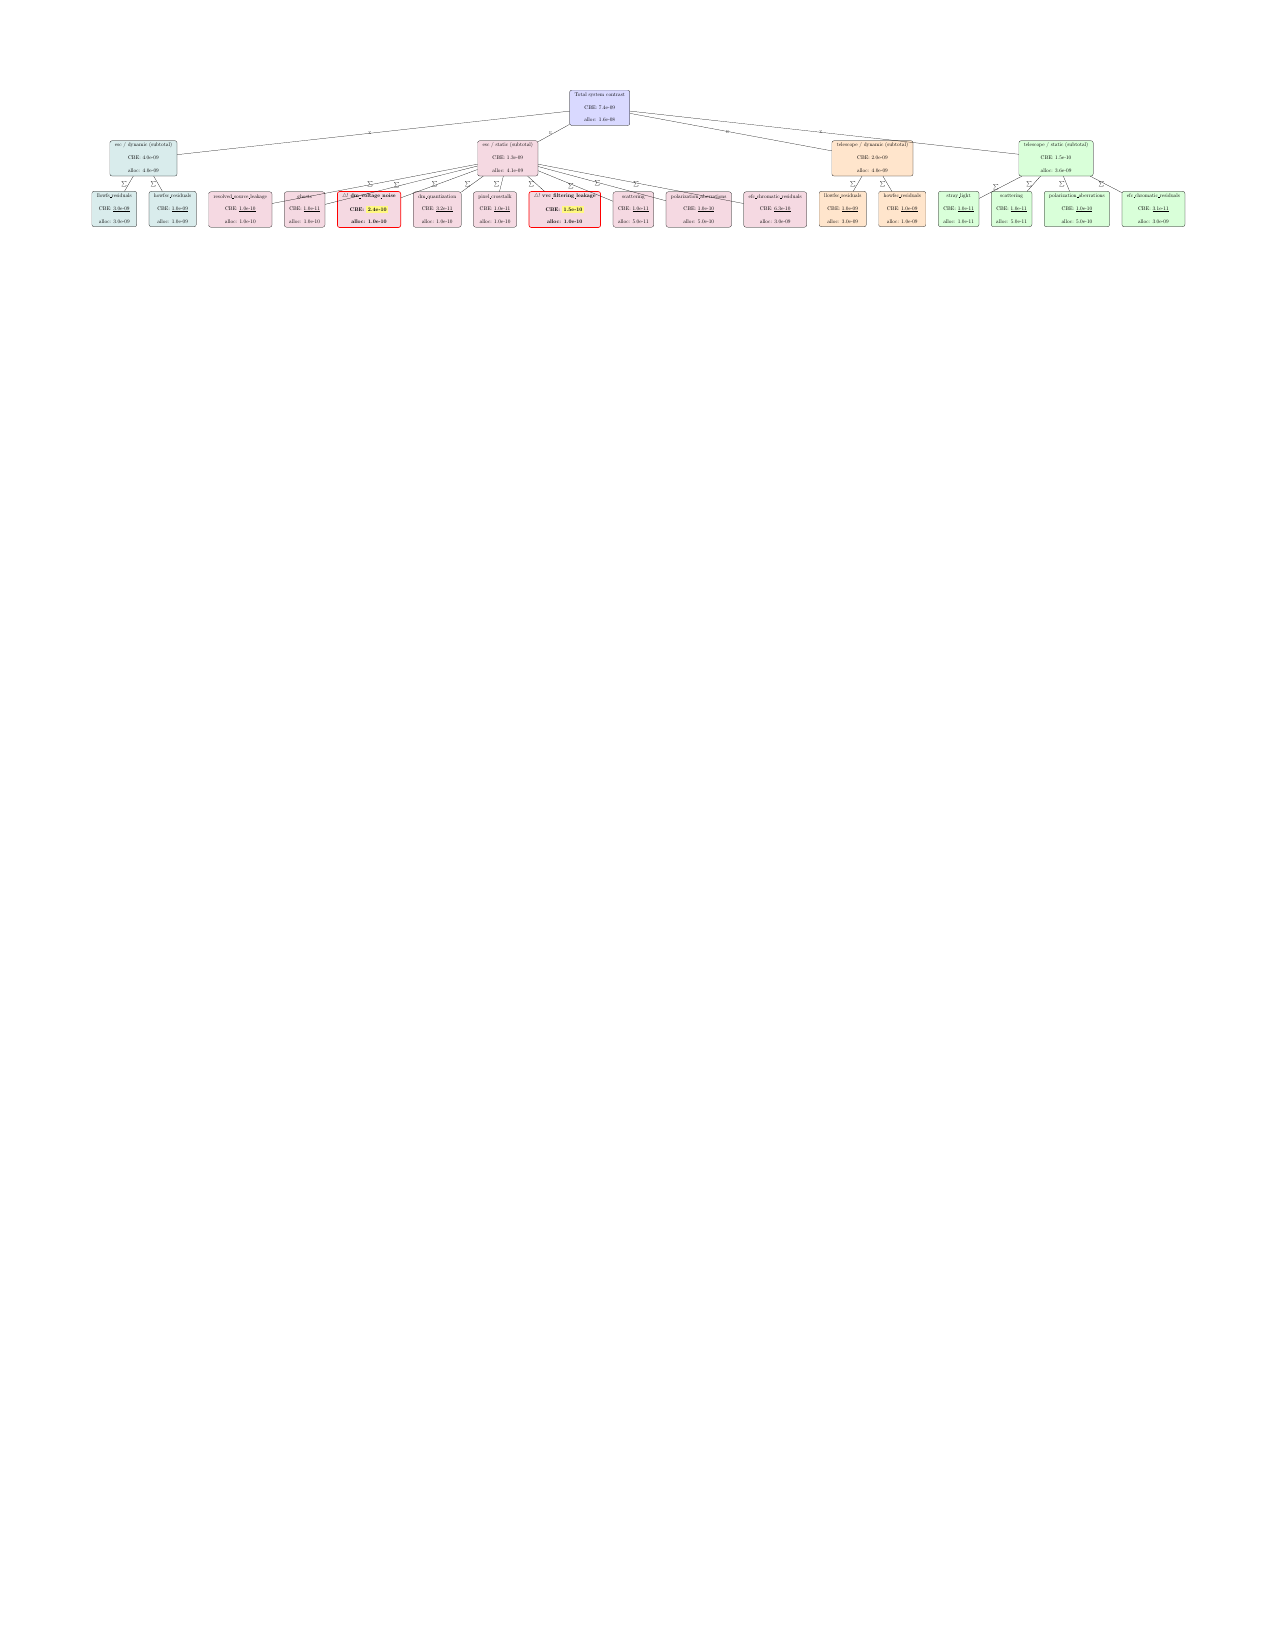

In [5]:
one_page_png(render_tikz(node, show="both", standalone=False, layout="forest"))
